In [4]:
"""
Prueba piloto: construir un mini dataset de carteles de cine con la API de TMDB.

Uso:
    pip install requests pandas
    export TMDB_API_KEY="tu_clave_v3"        # Windows PowerShell: $env:TMDB_API_KEY="..."
    python tmdb_pilot.py --per-cell 4 --out data_pilot

Con los valores por defecto (6 generos x 6 decadas x 4 peliculas) descarga ~140 carteles.
Salida:
    data_pilot/metadata.csv     <- el dataset (una fila por pelicula)
    data_pilot/posters/{id}.jpg <- carteles en w500 (500x750)
    data_pilot/raw/{id}.json    <- respuesta cruda de TMDB (para reproducibilidad)

Este producto usa la API de TMDB pero no esta avalado ni certificado por TMDB.
"""
import argparse
import hashlib
import json
import os
import random
import sys
import time
from pathlib import Path

import pandas as pd
import requests

os.environ["TMDB_API_KEY"] = "9bc46329bd12d593e26807ea2f38e6c6"


API = "https://api.themoviedb.org/3"
IMG = "https://image.tmdb.org/t/p/w500"

# Comprueba estos IDs con GET /genre/movie/list antes de un run grande.
GENRES = {
    "terror": 27,
    "comedia": 35,
    "ciencia_ficcion": 878,
    "romance": 10749,
    "animacion": 16,
    "accion": 28,
}
TARGET_IDS = set(GENRES.values())
DECADES = [(1970, 1979), (1980, 1989), (1990, 1999), (2000, 2009), (2010, 2019), (2020, 2025)]

SEED = 42
MIN_WORDS = 30
MIN_VOTES = 50


def get(session, path, params, retries=5):
    """GET con reintentos y espera ante 429."""
    for attempt in range(retries):
        r = session.get(f"{API}{path}", params=params, timeout=20)
        if r.status_code == 429:
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()
        time.sleep(0.05)  # cortesia con la API
        return r.json()
    raise RuntimeError(f"Demasiados 429 en {path}")


def valid(movie, genre_id):
    """Filtros de calidad. El filtro de 'un solo genero objetivo' se hace aqui
    (en cliente) para no depender de la semantica de without_genres."""
    ids = set(movie.get("genre_ids", []))
    if ids & TARGET_IDS != {genre_id}:
        return False
    if not movie.get("poster_path"):
        return False
    if len((movie.get("overview") or "").split()) < MIN_WORDS:
        return False
    return movie.get("original_language") == "en"


def discover_cell(session, genre_id, start, end, n, pool_pages, rng):
    """Candidatas de un genero y una decada, muestreadas al azar dentro
    de las primeras `pool_pages` paginas (reduce el sesgo hacia los blockbusters)."""
    pool = []
    for page in range(1, pool_pages + 1):
        data = get(session, "/discover/movie", {
            "with_genres": genre_id,
            "with_original_language": "en",
            "vote_count.gte": MIN_VOTES,
            "primary_release_date.gte": f"{start}-01-01",
            "primary_release_date.lte": f"{end}-12-31",
            "sort_by": "vote_count.desc",
            "include_adult": "false",
            "page": page,
        })
        pool += [m for m in data["results"] if valid(m, genre_id)]
        if page >= data.get("total_pages", 1):
            break
    rng.shuffle(pool)
    return pool[:n]


def fetch_detail(session, movie_id):
    """Detalle + keywords en una sola llamada."""
    return get(session, f"/movie/{movie_id}", {"append_to_response": "keywords"})


def download_poster(session, poster_path, dest):
    if dest.exists():
        return True
    r = session.get(f"{IMG}{poster_path}", timeout=30)
    if r.status_code != 200:
        return False
    dest.write_bytes(r.content)
    return True


def assign_split(group_key):
    """Particion por saga: todas las peliculas de una coleccion caen en la misma.
    Hash determinista (reproducible). En el piloto no estratifica por genero."""
    h = int(hashlib.md5(f"{SEED}-{group_key}".encode()).hexdigest(), 16) % 100
    if h < 10:
        return "holdout_gen"
    if h < 80:
        return "train"
    if h < 90:
        return "val"
    return "test"


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--per-cell", type=int, default=150, help="peliculas por genero y decada")
    ap.add_argument("--pool-pages", type=int, default=40, help="paginas de discover a muestrear")
    ap.add_argument("--out", default="data_pilot")
    args, _ = ap.parse_known_args()  # ignora los args que Jupyter inyecta (--f=...)

    key = os.environ.get("TMDB_API_KEY")
    if not key:
        sys.exit("Falta la variable de entorno TMDB_API_KEY")

    out = Path(args.out)
    (out / "posters").mkdir(parents=True, exist_ok=True)
    (out / "raw").mkdir(parents=True, exist_ok=True)

    session = requests.Session()
    session.params = {"api_key": key}  # type: ignore[assignment]
    rng = random.Random(SEED)

    rows, seen = [], set()
    for genre, gid in GENRES.items():
        for start, end in DECADES:
            cands = discover_cell(session, gid, start, end, args.per_cell, args.pool_pages, rng)
            print(f"{genre:16s} {start}s: {len(cands)} candidatas")
            for m in cands:
                mid = m["id"]
                if mid in seen:
                    continue
                seen.add(mid)

                raw_file = out / "raw" / f"{mid}.json"
                if raw_file.exists():  # reanudable: reutiliza lo ya descargado
                    detail = json.loads(raw_file.read_text(encoding="utf-8"))
                else:
                    detail = fetch_detail(session, mid)
                    raw_file.write_text(json.dumps(detail, ensure_ascii=False), encoding="utf-8")

                poster_file = out / "posters" / f"{mid}.jpg"
                if not download_poster(session, detail.get("poster_path"), poster_file):
                    print(f"  ! cartel no descargado: {mid}")
                    continue

                coll = detail.get("belongs_to_collection") or {}
                group = coll.get("id") or f"m{mid}"
                rows.append({
                    "tmdb_id": mid,
                    "title": detail.get("title"),
                    "year": (detail.get("release_date") or "")[:4],
                    "genre": genre,
                    "overview": detail.get("overview"),
                    "tagline": detail.get("tagline"),
                    "keywords": "|".join(k["name"] for k in detail.get("keywords", {}).get("keywords", [])),
                    "collection": coll.get("name"),
                    "poster_file": f"posters/{mid}.jpg",
                    "split": assign_split(group),
                })

    df = pd.DataFrame(rows).drop_duplicates("tmdb_id")
    df.to_csv(out / "metadata.csv", index=False, encoding="utf-8")

    print(f"\nListo: {len(df)} peliculas en {out / 'metadata.csv'}")
    print(df.groupby("genre").size().to_string())
    print(df.groupby("split").size().to_string())


if __name__ == "__main__":
    main()

terror           1970s: 93 candidatas
terror           1980s: 145 candidatas
terror           1990s: 104 candidatas
terror           2000s: 150 candidatas
terror           2010s: 150 candidatas
terror           2020s: 150 candidatas
comedia          1970s: 89 candidatas
comedia          1980s: 150 candidatas
comedia          1990s: 150 candidatas
comedia          2000s: 150 candidatas
comedia          2010s: 150 candidatas
comedia          2020s: 150 candidatas
ciencia_ficcion  1970s: 25 candidatas
ciencia_ficcion  1980s: 29 candidatas
ciencia_ficcion  1990s: 20 candidatas
ciencia_ficcion  2000s: 57 candidatas
ciencia_ficcion  2010s: 132 candidatas
ciencia_ficcion  2020s: 58 candidatas
romance          1970s: 27 candidatas
romance          1980s: 61 candidatas
romance          1990s: 133 candidatas
romance          2000s: 150 candidatas
romance          2010s: 150 candidatas
romance          2020s: 105 candidatas
animacion        1970s: 20 candidatas
animacion        1980s: 22 candidat

genre   terror  comedia  ciencia_ficcion  romance  animacion  accion  total
decada                                                                     
1970s       93       89               25       27         20      66    320
1980s      145      150               29       61         22     139    546
1990s      104      150               20      133         31     150    588
2000s      150      150               57      150         57     150    714
2010s      150      150              132      150        113     150    845
2020s      150      150               58      105         34     150    647


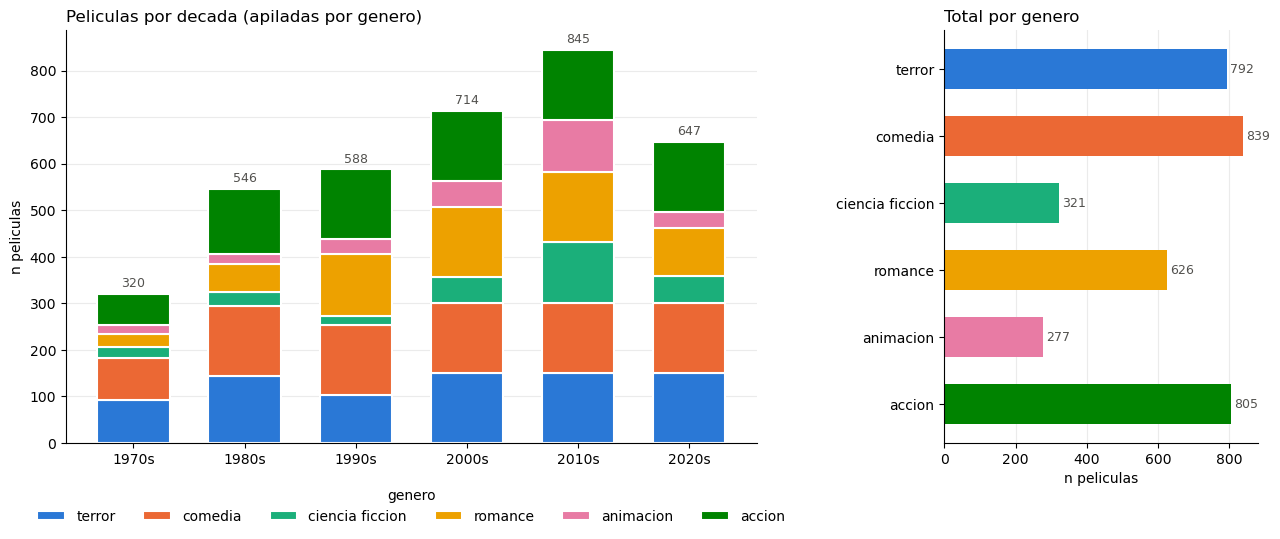

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data_pilot/metadata.csv")
df["decada"] = (df["year"] // 10 * 10).astype(int).astype(str) + "s"

generos = ["terror", "comedia", "ciencia_ficcion", "romance", "animacion", "accion"]
colores = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]  # orden fijo por genero

tabla = pd.crosstab(df["decada"], df["genre"]).reindex(columns=generos, fill_value=0)
print(tabla.assign(total=tabla.sum(axis=1)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [2.2, 1]})

# Izquierda: peliculas por decada, apiladas por genero
bottom = pd.Series(0, index=tabla.index)
for g, c in zip(generos, colores):
    ax1.bar(tabla.index, tabla[g], bottom=bottom, color=c, edgecolor="white",
            linewidth=1.5, width=0.65, label=g.replace("_", " "))
    bottom += tabla[g]
for x, tot in zip(tabla.index, bottom):
    ax1.text(x, tot + bottom.max() * 0.01, int(tot), ha="center", va="bottom", fontsize=9, color="#52514e")
ax1.set_title("Peliculas por decada (apiladas por genero)", loc="left", fontsize=12)
ax1.set_ylabel("n peliculas")
ax1.legend(title="genero", frameon=False, ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.08))

# Derecha: total por genero
tot_g = tabla.sum()
ax2.barh([g.replace("_", " ") for g in generos], tot_g.values, color=colores, height=0.6)
for i, v in enumerate(tot_g.values):
    ax2.text(v + tot_g.max() * 0.01, i, int(v), va="center", fontsize=9, color="#52514e")
ax2.invert_yaxis()
ax2.set_title("Total por genero", loc="left", fontsize=12)
ax2.set_xlabel("n peliculas")

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y" if ax is ax1 else "x", alpha=0.25)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()
